<a href="https://colab.research.google.com/github/CodeWithradhika/CSET343./blob/main/Lab8_Topic_Modelling_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET343 - Lab Assignment 8
## NLP & Topic Modelling (LDA) on Health-Related Headlines

Dataset: WuraolaOyewusi / Health-Related-Headlines-Datasets-for-Natural-Language-Processing (GitHub)

## Setup

In [1]:
!pip install -q pyLDAvis wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 63.8 MB/s eta 0:00:00


In [2]:
import os, re, glob, json, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
warnings.filterwarnings("ignore")

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

## Task 1: Data Preprocessing and Cleaning
### Load the dataset (clone the GitHub repo)

In [3]:
REPO = "Health-Related-Headlines-Datasets-for-Natural-Language-Processing"
if not os.path.exists(REPO):
    !git clone -q https://github.com/WuraolaOyewusi/{REPO}.git

# list all CSV / JSON files in the repo
files = [f for f in glob.glob(f"{REPO}/**/*", recursive=True)
         if f.lower().endswith((".csv", ".json", ".tsv"))]
print("Data files found:")
for f in files:
    print("  ", f)
assert files, "No data files found - check that the git clone above worked (repo name / internet)."

Data files found:
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_Management_News_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Clinical_Trials_Journals_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Antibiotic_Resistance_Related_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Substance_Abuse_and_Addiction_Related_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_management_Features_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Clinical_Trials_Related_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_Management_Related_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Antibiotic_Resistance_Journals_Headlines.csv
   Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Antibiotic_Resistance_Perspecti

In [4]:
# If you want a specific file, set it here, e.g. DATA_FILE = "<repo>/<file>.csv"
# Leave as None to auto-pick (prefers a file with "headline" in its name).
DATA_FILE = None

if DATA_FILE is None:
    pref = [f for f in files if "headline" in os.path.basename(f).lower()]
    DATA_FILE = (pref or files)[0]
print("Using:", DATA_FILE)

def load_any(path):
    if path.lower().endswith(".json"):
        try:
            return pd.read_json(path)
        except ValueError:
            return pd.read_json(path, lines=True)
    sep = "\t" if path.lower().endswith(".tsv") else ","
    try:
        return pd.read_csv(path, sep=sep)
    except UnicodeDecodeError:
        return pd.read_csv(path, sep=sep, encoding="latin-1")

df = load_any(DATA_FILE)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Using: Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_Management_News_Headlines.csv
Shape: (3693, 4)
Columns: ['Date', 'Source', 'Headlines', 'Teaser']


,Date,Source,Headlines,Teaser
0,May 2002,Medscape Medical News,'Pain Relief Ball' Cuts Opioid Use After Gynec...,It may be the new standard of care for postope...
1,May 2002,Medscape Medical News,Intradiscal Electrothermal Therapy Benefits Lo...,The therapy is an effective alternative to spi...
2,May 2002,Medscape Medical News,CT Scan Catches Life-Threatening Problems in P...,All 7 of the patients who died in the study di...
3,April 2002,Medscape Medical News,Breast-feeding Is Analgesic in Healthy Newborns,Breast-feeding also seemed to prevent the norm...
4,March 2002,Medscape Medical News,Aseptic Meningitis Cases Linked to Rofecoxib,"Recovery followed drug discontinuation, and re..."


In [5]:
# Pick the text column automatically (longest average text among object columns)
# Or set manually, e.g. TEXT_COL = "Headline"
TEXT_COL = None

if TEXT_COL is None:
    obj_cols = [col for col in df.columns if df[col].dtype == "object"]
    name_hint = [col for col in obj_cols
                 if any(k in col.lower() for k in ["headline", "title", "teaser", "text"])]
    cands = name_hint or obj_cols
    TEXT_COL = max(cands, key=lambda col: df[col].astype(str).str.len().mean())
print("Text column:", TEXT_COL)

df = df.dropna(subset=[TEXT_COL]).drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)
print("Rows after dropping NaN/duplicates:", len(df))

Text column: Teaser
Rows after dropping NaN/duplicates: 3693


### Cleaning: lowercasing, punctuation removal, tokenization, stop-word removal, lemmatization

In [6]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
# a few extra generic news words that carry no topic information
stop_words |= {"say", "says", "said", "new", "may", "could", "would", "us",
               "one", "get", "make", "also", "year", "show", "study"}

def clean_text(text):
    text = str(text).lower()                                       # lowercasing
    text = re.sub(r"http\S+|www\S+", " ", text)                      # remove URLs
    text = text.translate(str.maketrans("", "", string.punctuation))  # punctuation removal
    text = re.sub(r"[^a-z\s]", " ", text)                            # remove digits / symbols
    tokens = word_tokenize(text)                                   # tokenization
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]   # stop-word removal
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n")    # lemmatization
              for t in tokens]
    tokens = [t for t in tokens if t not in stop_words]
    return tokens

df["tokens"] = df[TEXT_COL].apply(clean_text)
df["clean_text"] = df["tokens"].apply(" ".join)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print("Documents after cleaning:", len(df))

Documents after cleaning: 3693


### Display a few cleaned samples

In [7]:
for i in range(8):
    print(f"Original : {df[TEXT_COL][i]}")
    print(f"Tokens   : {df['tokens'][i]}")
    print(f"Cleaned  : {df['clean_text'][i]}")
    print("-" * 80)

Original : It may be the new standard of care for postoperative pain control.
Tokens   : ['standard', 'care', 'postoperative', 'pain', 'control']
Cleaned  : standard care postoperative pain control
--------------------------------------------------------------------------------
Original : The therapy is an effective alternative to spinal fusion or chronic pain management.
Tokens   : ['therapy', 'effective', 'alternative', 'spinal', 'fusion', 'chronic', 'pain', 'management']
Cleaned  : therapy effective alternative spinal fusion chronic pain management
--------------------------------------------------------------------------------
Original : All 7 of the patients who died in the study did not receive an early CT scan.
Tokens   : ['patient', 'die', 'receive', 'early', 'scan']
Cleaned  : patient die receive early scan
--------------------------------------------------------------------------------
Original : Breast-feeding also seemed to prevent the normal rise in heart rate that accompa

## Task 2: Exploratory Text Analysis & Word Visualization
### Word frequency distribution

In [8]:
all_tokens = [t for toks in df["tokens"] for t in toks]
word_freq = Counter(all_tokens)

print("Total tokens :", len(all_tokens))
print("Unique words :", len(word_freq))
print("\nTop 20 most frequent words:")
freq_df = pd.DataFrame(word_freq.most_common(20), columns=["word", "count"])
display(freq_df)

Total tokens : 53280
Unique words : 7689

Top 20 most frequent words:


,word,count
0,pain,1159
1,patient,1005
2,use,583
3,opioid,514
4,drug,502
5,treatment,422
6,risk,332
7,suggest,303
8,increase,260
9,reduce,259


### Top 20 frequent words (bar plot)

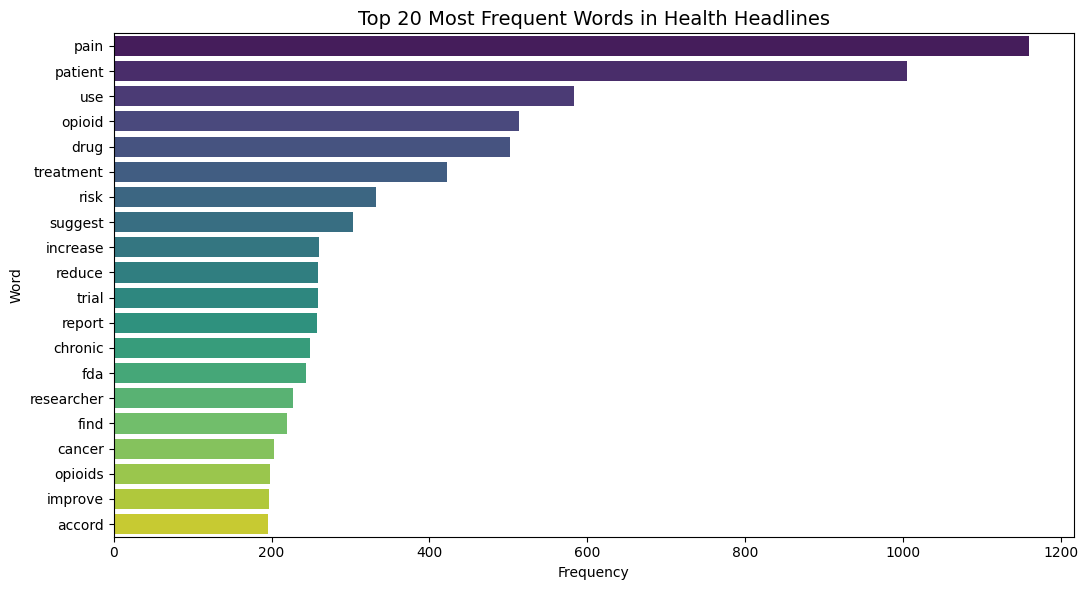

In [9]:
plt.figure(figsize=(11, 6))
sns.barplot(data=freq_df, x="count", y="word", palette="viridis")
plt.title("Top 20 Most Frequent Words in Health Headlines", fontsize=14)
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

### Word cloud

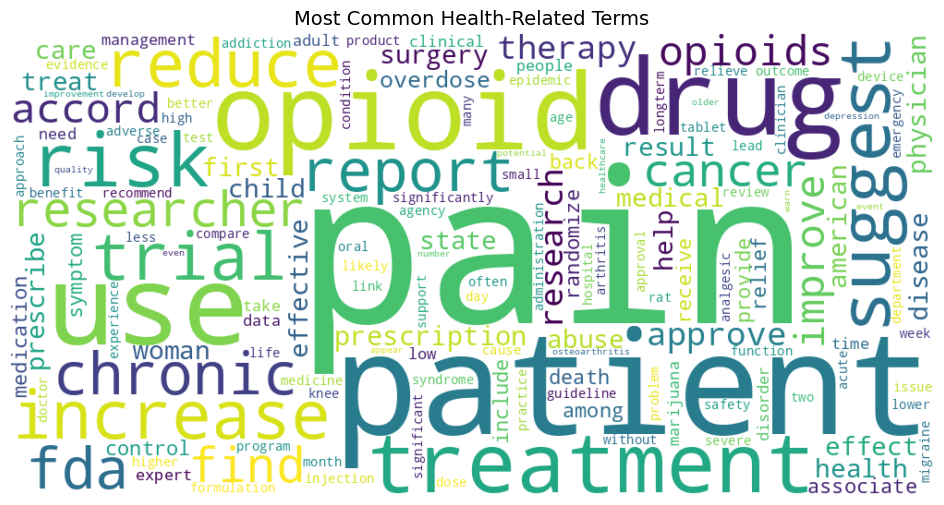

In [10]:
wc = WordCloud(width=1000, height=500, background_color="white",
               max_words=150, colormap="viridis").generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Health-Related Terms", fontsize=14)
plt.show()

## Task 3: Topic Modelling using LDA
### Build document-term matrix

In [11]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer = CountVectorizer(max_df=0.95, min_df=5, max_features=5000)
dtm = vectorizer.fit_transform(df["clean_text"])
print("Document-term matrix shape:", dtm.shape)

Document-term matrix shape: (3693, 1837)


### Train LDA

In [12]:
N_TOPICS = 5   # change if you want more / fewer topics

lda = LatentDirichletAllocation(n_components=N_TOPICS, max_iter=20,
                                learning_method="batch", random_state=42)
lda.fit(dtm)
print("LDA trained. Perplexity:", round(lda.perplexity(dtm), 2))

LDA trained. Perplexity: 960.11


### Top 5 words per topic

In [13]:
feature_names = vectorizer.get_feature_names_out()

for idx, topic in enumerate(lda.components_):
    top_idx = topic.argsort()[::-1][:5]
    print(f"Topic {idx + 1}: " + ", ".join(feature_names[top_idx]))

Topic 1: pain, patient, suggest, chronic, reduce
Topic 2: patient, health, pain, physician, emergency
Topic 3: fda, approve, pain, drug, opioid
Topic 4: opioid, drug, use, prescription, state
Topic 5: cancer, use, patient, risk, child


### Topic-word bar charts (matplotlib)

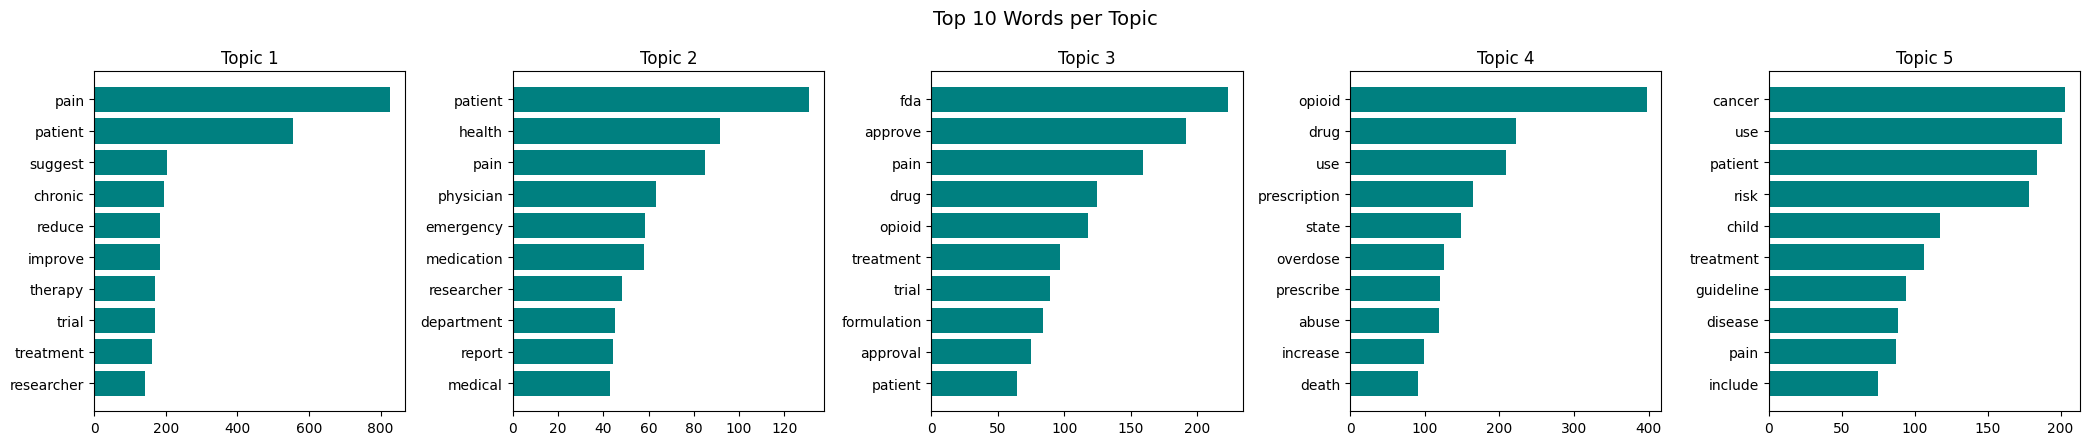

In [14]:
fig, axes = plt.subplots(1, N_TOPICS, figsize=(4.2 * N_TOPICS, 4.5), sharex=False)
if N_TOPICS == 1:
    axes = [axes]
for idx, (ax, topic) in enumerate(zip(axes, lda.components_)):
    top_idx = topic.argsort()[::-1][:10]
    ax.barh(feature_names[top_idx][::-1], topic[top_idx][::-1], color="teal")
    ax.set_title(f"Topic {idx + 1}")
plt.suptitle("Top 10 Words per Topic", fontsize=14)
plt.tight_layout()
plt.show()

### Dominant topic per document

In [15]:
doc_topic = lda.transform(dtm)
df["dominant_topic"] = doc_topic.argmax(axis=1) + 1

print("Documents per topic:")
print(df["dominant_topic"].value_counts().sort_index())
display(df[[TEXT_COL, "dominant_topic"]].head(10))

Documents per topic:
dominant_topic
1    1335
2     426
3     458
4     790
5     684
Name: count, dtype: int64


,Teaser,dominant_topic
0,It may be the new standard of care for postope...,1
1,The therapy is an effective alternative to spi...,1
2,All 7 of the patients who died in the study di...,5
3,Breast-feeding also seemed to prevent the norm...,1
4,"Recovery followed drug discontinuation, and re...",2
5,COX-2 inhibitors are now to be considered the ...,5
6,A small study using one variety of magnet for ...,1
7,"For palliation, single-fraction radiotherapy w...",1
8,The degree of duct dilation is associated with...,1
9,Fifty of the 62 patients achieved a high degre...,1


### Visualize with pyLDAvis

In [16]:
import pyLDAvis
pyLDAvis.enable_notebook()

try:
    import pyLDAvis.lda_model as ldavis_sk          # pyLDAvis >= 3.4
except ImportError:
    import pyLDAvis.sklearn as ldavis_sk            # older versions

vis = ldavis_sk.prepare(lda, dtm, vectorizer, mds="tsne")
pyLDAvis.save_html(vis, "lda_visualization.html")   # saved copy for submission
vis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=               x          y  topics  cluster       Freq
topic                                                  
0     -48.027710 -14.470527       1        1  32.468539
3     -24.761229  56.828434       2        1  21.486450
4      46.963299  64.123451       3        1  18.979137
2      88.438942   1.703609       4        1  13.935686
1      22.676262 -28.744576       5        1  13.130188, topic_info=           Term         Freq        Total Category  logprob  loglift
1142     opioid   496.000000   496.000000  Default  30.0000  30.0000
614         fda   238.000000   238.000000  Default  29.0000  29.0000
120     approve   187.000000   187.000000  Default  28.0000  28.0000
1173       pain  1105.000000  1105.000000  Default  27.0000  27.0000
232      cancer   195.000000   195.000000  Default  26.0000  26.0000
...         ...          ...          ...      ...      ...      ...
483      doctor    25.289792    80.289145   Topic5  -5.4327   0.8750
1622    suggest    33.119253   289.735853   Topic5  -5.1630  -0.1386
631        find    28.133133   210.359560   Topic5  -5.3261   0.0184
1718  treatment    28.166359   405.700649   Topic5  -5.3250  -0.6372
1389     reduce    27.080390   247.620782   Topic5  -5.3643  -0.1828

[345 rows x 6 columns], token_table=      Topic      Freq            Term
term                                 
7         2  0.827145           abuse
7         4  0.166880           abuse
8         4  0.987898  abusedeterrent
13        1  0.540075          accord
13        2  0.064167          accord
...     ...       ...             ...
1826      5  0.957314           write
1832      1  0.023075           young
1832      3  0.807625           young
1832      5  0.161525           young
1836      3  0.946614          zoster

[526 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 4, 5, 3, 2])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
